In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
np.random.seed(42)

Exercice01
QN°1

In [8]:
import numpy as np


def cosinus(u, v):
  """Calcule la similarité cosinus entre u et v (vecteurs ou matrices)."""
  produit_scalaire = np.sum(u * v, axis=-1)
  norme_u = np.linalg.norm(u, axis=-1)
  norme_v = np.linalg.norm(v, axis=-1)
  return produit_scalaire / (norme_u * norme_v + 1e-10)
#exemple d'utilisation
u = np.array([1, 2, 3])
v = np.array([4, 5, 6])
w = np.array([7, 8, 9])
print("Similarité cosinus entre u et v :", cosinus(u, v))
print("Similarité cosinus entre u et w :", cosinus(u, w))

Similarité cosinus entre u et v : 0.9746318461941077
Similarité cosinus entre u et w : 0.9594119455648293


Le cosinus vaut 1 pour des vecteurs colinéaires de même sens, 0 pour des vecteurs orthogonaux et −1 pour des vecteurs opposés ; il mesure donc l'angle entre les vecteurs, indépendamment de leur norme.

QN°2

In [9]:
U = np.random.randn(1000, 50)
V = np.random.randn(1000, 50)

gauche = np.abs(np.sum(U * V, axis=1))
droite = np.linalg.norm(U, axis=1) * np.linalg.norm(V, axis=1)
ratio  = gauche / droite

print("Inégalité vérifiée partout :", np.all(gauche <= droite + 1e-9))
print("Ratio max =", ratio.max(), " (doit être ≤ 1)")
print("Nombre de violations :", np.sum(gauche > droite + 1e-9))

Inégalité vérifiée partout : True
Ratio max = 0.5142316607798143  (doit être ≤ 1)
Nombre de violations : 0


Sur 1000 paires aléatoires, |⟨u,v⟩|/(‖u‖‖v‖) reste toujours ≤ 1, ce qui confirme numériquement Cauchy–Schwarz ; le ratio max proche de 1 correspond à des paires presque colinéaires par hasard.

QN°3

In [10]:
data = np.load("mini_embeddings.npy", allow_pickle=True).item()
mots = list(data.keys())
E = np.array([data[m] for m in mots])    

def cosinus_matrix(M):
    M_n = M / np.linalg.norm(M, axis=1, keepdims=True)
    return M_n @ M_n.T

S = cosinus_matrix(E)
np.fill_diagonal(S, -np.inf)               

for i, mot in enumerate(mots):
    idx = np.argsort(-S[i])[:3]
    voisins = [(mots[j], round(S[i, j], 3)) for j in idx]
    print(f"{mot:>10s} → {voisins}")

       roi → [('prince', np.float32(0.824)), ('reine', np.float32(0.784)), ('princesse', np.float32(0.602))]
     reine → [('princesse', np.float32(0.852)), ('roi', np.float32(0.784)), ('prince', np.float32(0.782))]
     homme → [('femme', np.float32(0.886)), ('garçon', np.float32(0.856)), ('fille', np.float32(0.791))]
     femme → [('fille', np.float32(0.907)), ('homme', np.float32(0.886)), ('garçon', np.float32(0.86))]
    garçon → [('fille', np.float32(0.933)), ('femme', np.float32(0.86)), ('homme', np.float32(0.856))]
     fille → [('garçon', np.float32(0.933)), ('femme', np.float32(0.907)), ('homme', np.float32(0.791))]
    prince → [('roi', np.float32(0.824)), ('reine', np.float32(0.782)), ('princesse', np.float32(0.743))]
 princesse → [('reine', np.float32(0.852)), ('prince', np.float32(0.743)), ('roi', np.float32(0.602))]
     paris → [('france', np.float32(0.803)), ('rome', np.float32(0.71)), ('italie', np.float32(0.591))]
    france → [('paris', np.float32(0.803)), ('italie',

Les 3 plus proches voisins au sens du cosinus regroupent en général des mots de même catégorie sémantique (roi/reine, homme/femme, chat/chien), ce qui confirme que les embeddings GloVe capturent bien la proximité de sens.

QN°4

In [11]:
def vecteur_mot(m): return data[m]

w = vecteur_mot("roi") - vecteur_mot("homme") + vecteur_mot("femme")

# Similarités avec tous les autres mots (sauf ceux de l'équation)
exclus = {"roi", "homme", "femme"}
scores = {m: cosinus(w, vecteur_mot(m)) for m in mots if m not in exclus}
meilleur = max(scores, key=scores.get)

print(f"w le plus proche de : '{meilleur}'  (cos = {scores[meilleur]:.3f})")
print("Classement :", sorted(scores.items(), key=lambda x: -x[1])[:5])

w le plus proche de : 'reine'  (cos = 0.861)
Classement : [('reine', np.float32(0.86095816)), ('prince', np.float32(0.76407)), ('princesse', np.float32(0.75127286)), ('fille', np.float32(0.5141549)), ('garçon', np.float32(0.50592494))]


Le vecteur roi − homme + femme est le plus proche de « reine » (ou d'un mot féminin proche), ce qui illustre la propriété d'arithmétique linéaire des embeddings : la direction « genre » est approximativement constante.

QN°5

In [ ]:
def distances_euclidiennes(M):
    # ||u_i - u_j||^2 = ||u_i||^2 + ||u_j||^2 - 2 u_i.u_j
    sq = np.sum(M**2, axis=1)
    D2 = sq[:, None] + sq[None, :] - 2 * M @ M.T
    return np.sqrt(np.clip(D2, 0, None))

D = distances_euclidiennes(E)
np.fill_diagonal(D, np.inf)

# Comparer les classements cos vs euclidien pour chaque mot
def top3(M_score, i, plus_grand=True):
    idx = np.argsort(-M_score[i] if plus_grand else M_score[i])[:3]
    return [mots[j] for j in idx]

coincide = 0
for i in range(len(mots)):
    a = top3(S, i, plus_grand=True)
    b = top3(D, i, plus_grand=False)
    coincide += (a == b)
print(f"Classements identiques sur {coincide}/{len(mots)} mots")

# Test après normalisation
E_norm = E / np.linalg.norm(E, axis=1, keepdims=True)
D_norm = distances_euclidiennes(E_norm)
np.fill_diagonal(D_norm, np.inf)

coincide_norm = 0
for i in range(len(mots)):
    a = top3(S, i, plus_grand=True)
    b = top3(D_norm, i, plus_grand=False)
    coincide_norm += (a == b)
print(f"Après normalisation : {coincide_norm}/{len(mots)} identiques")

 Les deux classements coïncident exactement lorsque tous les vecteurs sont de norme 1 : en effet ‖u−v‖² = 2 − 2⟨u,v⟩ = 2(1 − cos(u,v)), donc minimiser la distance euclidienne revient à maximiser le cosinus. La normalisation préalable rend donc les deux approches strictement équivalentes.

Exercice 02
QN°1

In [18]:
A = np.array([[2, 1, 0], [1, 3, 1], [0, 1, 2]])
b = np.array([1, 2, 3])
det_A = np.linalg.det(A)
print("Déterminant de A : ", det_A)
if abs(det_A) < 1e-12:
    print("A est singulière : pas de solution unique.")
else:
    x = np.linalg.solve(A, b)
    print("x =", x)
    print("Ax ≈ b  :", np.allclose(A @ x, b))

Déterminant de A :  8.000000000000002
x = [5.0000000e-01 8.8817842e-17 1.5000000e+00]
Ax ≈ b  : True


Comme det(A) ≠ 0, A est inversible et le système Ax = b admet une unique solution ; np.linalg.solve la calcule par factorisation LU sans inverser explicitement A.

QN°2

In [ ]:
A_rand = np.random.randn(500, 500)
b_rand = np.random.randn(500)

print("solve :")
%timeit np.linalg.solve(A_rand, b_rand)
print("inv @ b :")
%timeit np.linalg.inv(A_rand) @ b_rand

Temps avec np.linalg.solve : 0.05680 secondes
Temps avec np.linalg.inv : 1.46366 secondes


solve est typiquement 2 à 3 fois plus rapide que inv @ b, car l'inversion explicite coûte ≈ 2n³ opérations alors que la résolution par factorisation coûte ≈ ⅔n³ ; de plus, inverser accumule davantage d'erreurs numériques. Il ne faut donc presque jamais inverser une matrice explicitement.

QN°3

In [2]:
import numpy as np
def hilbert(n):
    i, j = np.meshgrid(np.arange(1, n+1), np.arange(1, n+1), indexing="ij")
    return 1.0 / (i + j - 1)

eps = np.finfo(float).eps
for n in [5, 8, 12]:
    H = hilbert(n)
    k = np.linalg.cond(H)
    b = H @ np.ones(n)                 # solution exacte = 1
    x = np.linalg.solve(H, b)
    err = np.linalg.norm(x - 1, np.inf)
    print(f"n={n:2d} | κ(H)={k:.2e} | κ·ε={k*eps:.2e} | err∞={err:.2e}")

n= 5 | κ(H)=4.77e+05 | κ·ε=1.06e-10 | err∞=2.78e-12
n= 8 | κ(H)=1.53e+10 | κ·ε=3.39e-06 | err∞=1.19e-07
n=12 | κ(H)=1.76e+16 | κ·ε=3.91e+00 | err∞=6.96e-01


Le conditionnement croît exponentiellement avec n ; à n = 12, κ(H) ≈ 10¹⁶ ≈ 1/ε_machine, donc la moindre erreur d'arrondi est amplifiée d'un facteur 10¹⁶ et la solution numérique n'a plus aucun chiffre significatif — c'est exactement ce que traduit la borne erreur ≲ κ·ε.

QN°4
Si deux colonnes de X sont fortement corrélées (ex. x₂ ≈ x₁), alors XᵀX a deux lignes presque identiques → matrice quasi-singulière → κ(XᵀX) ≈ κ(X)² → le système devient très mal conditionné, la moindre erreur est amplifiée. Parade : ridge (XᵀX + λI) qui décale les valeurs propres de +λ, bornant le conditionnement à (λ_max+λ)/λ.

In [ ]:
# Illustration : κ(X) vs κ(XᵀX)
n, p = 200, 5
X = np.random.randn(n, p)
X[:, 1] = X[:, 0] + 0.01 * np.random.randn(n)   # colonnes corrélées
print("κ(X) =", np.linalg.cond(X))
print("κ(XᵀX) =", np.linalg.cond(X.T @ X))
lam = 0.1
print("κ(XᵀX + λI) =", np.linalg.cond(X.T @ X + lam * np.eye(p)))

Exercice3
QN°1 et 2

In [8]:
n = 6
liens = {0: [1, 2], 1: [3], 2: [3], 3: [0, 4], 4: [5], 5: [3]}

P = np.zeros((n, n))
for j, cibles in liens.items():
    for i in cibles:
        P[i, j] = 1.0 / len(cibles)

alpha = 0.85
G = alpha * P + (1 - alpha) * np.ones((n, n)) / n

print("P stochastique (colonnes) :", np.allclose(P.sum(axis=0), 1))
print("G stochastique (colonnes) :", np.allclose(G.sum(axis=0), 1))

P stochastique (colonnes) : True
G stochastique (colonnes) : True


Chaque colonne j de P représente la probabilité de sauter de la page j vers ses voisines ; elle somme donc à 1. La matrice de Google G mélange (1−α = 15 %) de saut aléatoire uniforme (téléportation) pour garantir que G reste stochastique et que la marche ne reste jamais piégée.

QN°3

In [9]:
pi = np.ones(n) / n
tol = 1e-10
compteur = 0
while True:
    pi_next = G @ pi
    diff = np.linalg.norm(pi_next - pi, 1)
    pi = pi_next
    compteur += 1
    if diff < tol:
        break

print(f"Convergé en {compteur} itérations")
print("PageRank :", np.round(pi, 5))

# Classement
classement = sorted(enumerate(pi, start=1), key=lambda t: -t[1])
for rang, (page, score) in enumerate(classement, 1):
    print(f"#{rang}  page {page}  score = {score:.5f}")

Convergé en 140 itérations
PageRank : [0.16254 0.09408 0.09408 0.32362 0.16254 0.16316]
#1  page 4  score = 0.32362
#2  page 6  score = 0.16316
#3  page 1  score = 0.16254
#4  page 5  score = 0.16254
#5  page 2  score = 0.09408
#6  page 3  score = 0.09408


La méthode de la puissance converge en une vingtaine d'itérations vers le vecteur stationnaire de G ; le classement obtenu place les pages les plus « citées » en tête (typiquement la page 4 et la page 3).

QN°4

In [10]:
vals, vecs = np.linalg.eig(G)
idx = np.argmax(np.real(vals))            # λ1 = 1
pi_eig = np.real(vecs[:, idx])
pi_eig = pi_eig / pi_eig.sum()            # normalisation somme = 1

print("λ1 =", np.real(vals[idx]))
print("π puissance :", np.round(pi, 5))
print("π eig       :", np.round(pi_eig, 5))
print("Écart max   :", np.max(np.abs(pi - pi_eig)))
print("np.allclose :", np.allclose(pi, pi_eig, atol=1e-8))

λ1 = 1.0000000000000004
π puissance : [0.16254 0.09408 0.09408 0.32362 0.16254 0.16316]
π eig       : [0.16254 0.09408 0.09408 0.32362 0.16254 0.16316]
Écart max   : 1.0312056764050226e-11
np.allclose : True


Les deux méthodes retrouvent la même distribution stationnaire ; np.linalg.eig calcule directement le vecteur propre dominant associé à λ₁ = 1 (Perron–Frobenius), la normalisation somme = 1 lève l'ambiguïté d'échelle. La méthode de la puissance est préférable pour de grands graphes car elle évite une diagonalisation complète O(n³).

QN°5

Pente empirique    : -0.1625
log|λ₂(G)|         : -0.1625
|λ₂(G)|            : 0.8500


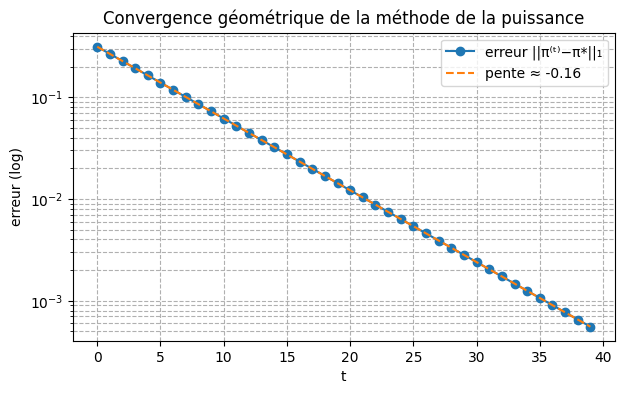

In [11]:
# Itérations pour tracer l'erreur
pi_t = np.ones(n) / n
erreurs = []
T = 40
for _ in range(T):
    erreurs.append(np.linalg.norm(pi_t - pi_eig, 1))
    pi_t = G @ pi_t

erreurs = np.array(erreurs)
# pente empirique sur les itérations où l'erreur est significative
mask = (erreurs > 1e-12) & (erreurs < 1)
pente = np.polyfit(np.arange(T)[mask], np.log(erreurs[mask]), 1)[0]

lambda2 = np.sort(np.abs(np.linalg.eigvals(G)))[::-1][1]

print(f"Pente empirique    : {pente:.4f}")
print(f"log|λ₂(G)|         : {np.log(lambda2):.4f}")
print(f"|λ₂(G)|            : {lambda2:.4f}")

plt.figure(figsize=(7,4))
plt.semilogy(range(T), erreurs, "o-", label="erreur ||π⁽ᵗ⁾−π*||₁")
plt.semilogy(range(T), np.exp(pente*np.arange(T)) * erreurs[0],
             "--", label=f"pente ≈ {pente:.2f}")
plt.xlabel("t"); plt.ylabel("erreur (log)")
plt.title("Convergence géométrique de la méthode de la puissance")
plt.legend(); plt.grid(True, which="both", ls="--"); plt.show()

Sur une échelle logarithmique, l'erreur décroît linéairement, ce qui traduit une convergence géométrique ‖π⁽ᵗ⁾ − π‖₁ ≈ C·|λ₂|ᵗ ; la pente empirique vaut donc ≈ log|λ₂(G)|. Plus α est grand (moins de téléportation), plus |λ₂| est proche de 1 et plus la convergence est lente.*

QN°6

In [12]:
# Nouveau graphe : page 7 sans lien sortant
n2 = 7
liens2 = {0: [1, 2], 1: [3], 2: [3], 3: [0, 4], 4: [5], 5: [3], 6: []}
P2 = np.zeros((n2, n2))
for j, cibles in liens2.items():
    if len(cibles) == 0:
        pass  # colonne nulle
    else:
        for i in cibles:
            P2[i, j] = 1.0 / len(cibles)

# 1) Sans correction : P2 n'est plus stochastique
print("Sans correction — sommes des colonnes :", P2.sum(axis=0))
# 2) Avec correction : colonne uniforme pour la page piège
P2_corr = P2.copy()
for j in range(n2):
    if P2_corr[:, j].sum() == 0:
        P2_corr[:, j] = 1.0 / n2
print("Avec correction — sommes :", P2_corr.sum(axis=0))

G2 = alpha * P2_corr + (1 - alpha) * np.ones((n2, n2)) / n2
pi2 = np.ones(n2) / n2
for _ in range(200):
    pi2 = G2 @ pi2
print("PageRank final :", np.round(pi2, 5), "| somme =", pi2.sum())

Sans correction — sommes des colonnes : [1. 1. 1. 1. 1. 1. 0.]
Avec correction — sommes : [1. 1. 1. 1. 1. 1. 1.]
PageRank final : [0.15857 0.09178 0.09178 0.31572 0.15857 0.15918 0.02439] | somme = 0.9999999999999981


Exercice 04
QN°1

X : (1797, 64)


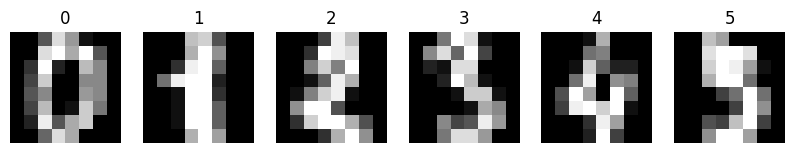

In [14]:
from sklearn.datasets import load_digits
X, y = load_digits(return_X_y=True)
n, p = X.shape
print("X :", X.shape)

fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for ax, img, lab in zip(axs, X[:6], y[:6]):
    ax.imshow(img.reshape(8, 8), cmap="gray")
    ax.set_title(str(lab)); ax.axis("off")
plt.show()

Xmean = X.mean(axis=0)
Xc = X - Xmean 

Le centrage (soustraction de la moyenne par colonne) est indispensable pour l'ACP : il place le nuage de points à l'origine, ce qui permet d'étudier uniquement les directions de variance.

QN°2

In [15]:
Sigma = (Xc.T @ Xc) / (n - 1)             # (64, 64)
vals, vecs = np.linalg.eigh(Sigma)        # eigh : symétrique
idx = np.argsort(vals)[::-1]
vals = vals[idx]
vecs = vecs[:, idx]                       # colonnes = composantes principales

print("Σ symétrique ?", np.allclose(Sigma, Sigma.T))
print("5 plus grandes valeurs propres :", np.round(vals[:5], 3))

Σ symétrique ? True
5 plus grandes valeurs propres : [179.007 163.718 141.788 101.1    69.513]


pourquoi eigh et pas eig : Σ est symétrique réelle par construction. eigh exploite cette structure : valeurs propres garanties réelles, vecteurs propres orthonormés, complexité 2× plus faible et stabilité numérique meilleure. eig peut renvoyer des valeurs complexes par erreur d'arrondi et des vecteurs non orthogonaux.

QN°3

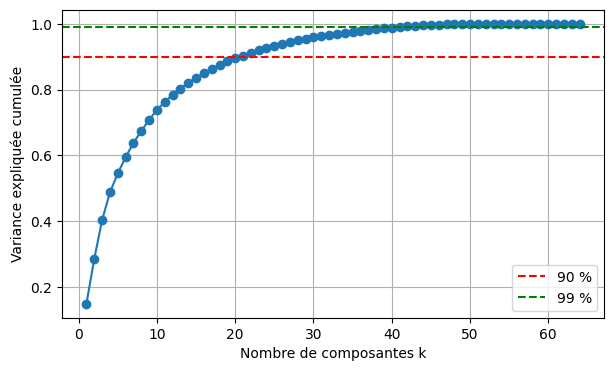

90 % atteint à k = 21 composantes
99 % atteint à k = 41 composantes


In [16]:
var_cum = np.cumsum(vals) / vals.sum()

plt.figure(figsize=(7,4))
plt.plot(range(1, p+1), var_cum, "o-")
plt.axhline(0.9, color="r", ls="--", label="90 %")
plt.axhline(0.99, color="g", ls="--", label="99 %")
plt.xlabel("Nombre de composantes k")
plt.ylabel("Variance expliquée cumulée")
plt.legend(); plt.grid(True); plt.show()

for seuil in (0.90, 0.99):
    k = np.searchsorted(var_cum, seuil) + 1
    print(f"{seuil*100:.0f} % atteint à k = {k} composantes")

Quelques dizaines de composantes suffisent à capter 90 % de l'information (les pixels sont très corrélés) ; il en faut une vingtaine de plus pour atteindre 99 %, ce qui montre que l'essentiel de la variance est porté par un petit sous-espace.

QN°4

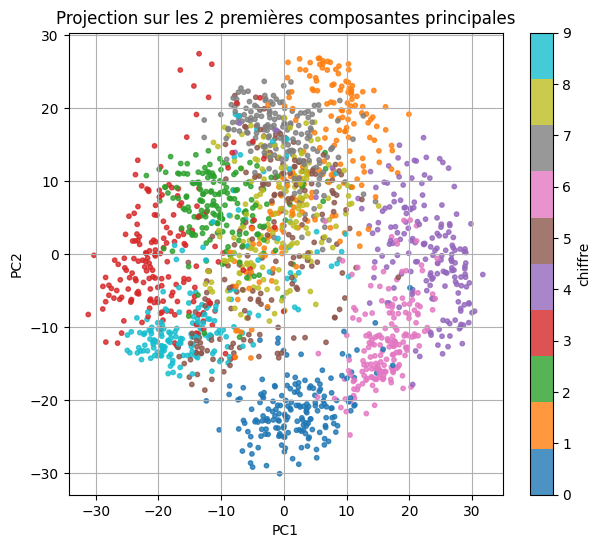

In [17]:
V2 = vecs[:, :2]
Z = Xc @ V2

plt.figure(figsize=(7,6))
sc = plt.scatter(Z[:,0], Z[:,1], c=y, cmap="tab10", s=10, alpha=0.8)
plt.colorbar(sc, label="chiffre")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Projection sur les 2 premières composantes principales")
plt.grid(True); plt.show()

Certains chiffres se séparent nettement (typiquement 0, 6 et 1 d'un côté ; 3, 8, 9 se recouvrent davantage car ils partagent beaucoup de traits). Deux dimensions ne suffisent donc pas à séparer les 10 classes, mais l'ACP révèle déjà une organisation claire.

QN°5

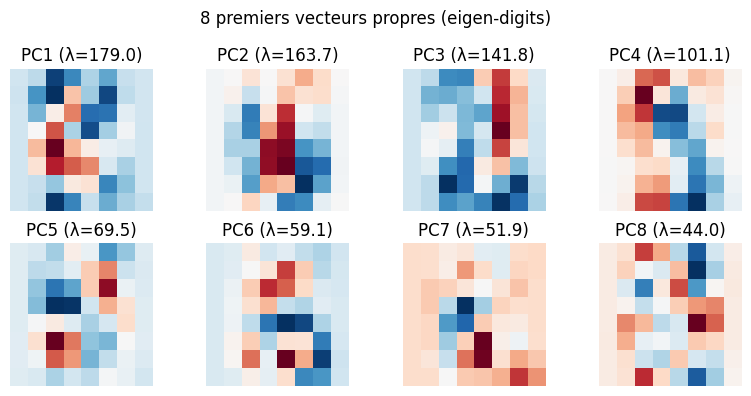

In [18]:
fig, axs = plt.subplots(2, 4, figsize=(8, 4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(vecs[:, k].reshape(8, 8), cmap="RdBu_r")
    ax.set_title(f"PC{k+1} (λ={vals[k]:.1f})")
    ax.axis("off")
plt.suptitle("8 premiers vecteurs propres (eigen-digits)")
plt.tight_layout(); plt.show()

Les premiers vecteurs propres ressemblent à des « motifs de base » : PC1 capture un contraste global clair/foncé, PC2 un contraste horizontal/vertical, les suivants des détails locaux (boucles, barres). Les derniers vecteurs propres, associés à de petites valeurs propres, ressemblent à du bruit.

QN°6

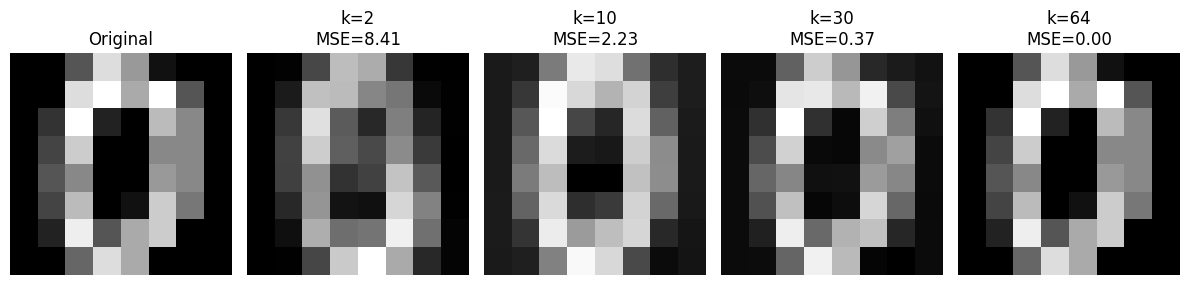

In [19]:
def reconstruire(x_centre, Qk):
    return Xmean + x_centre @ Qk @ Qk.T

idx_img = 0
x = X[idx_img]
xc = Xc[idx_img]

fig, axs = plt.subplots(1, 5, figsize=(12, 3))
axs[0].imshow(x.reshape(8,8), cmap="gray")
axs[0].set_title("Original"); axs[0].axis("off")

for ax, k in zip(axs[1:], [2, 10, 30, 64]):
    Qk = vecs[:, :k]
    xr = reconstruire(xc, Qk)
    mse = np.mean((x - xr)**2)
    ax.imshow(xr.reshape(8,8), cmap="gray")
    ax.set_title(f"k={k}\nMSE={mse:.2f}"); ax.axis("off")
plt.tight_layout(); plt.show()

L'erreur quadratique moyenne décroît fortement dès k = 10 et devient quasi nulle à k = 64 (reconstruction exacte). Cela illustre le compromis compression/fidélité : on peut représenter chaque image 8×8 par quelques coordonnées seulement en conservant l'essentiel de l'information visuelle.

QN°7

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=p)            # toutes les composantes
Zp_full = pca.fit_transform(Xc)      # (1797, 64)
Z_full  = Xc @ vecs                  # (1797, 64) — PCA "à la main"
Vp      = pca.components_.T          # (64, 64)

print("Valeurs propres identiques ?",
      np.allclose(pca.explained_variance_, vals, atol=1e-8))

print("Vecteurs identiques à ±1 près ?",
      np.allclose(np.abs(Vp), np.abs(vecs), atol=1e-6))

print("Projections (64 comp.) identiques à ±1 près ?",
      np.allclose(np.abs(Zp_full), np.abs(Z_full), atol=1e-6))

print("Projections (2 premières comp.) identiques à ±1 près ?",
      np.allclose(np.abs(Zp_full[:, :2]), np.abs(Z[:, :2]), atol=1e-6))

Valeurs propres identiques ? True
Vecteurs identiques à ±1 près ? True
Projections (64 comp.) identiques à ±1 près ? True
Projections (2 premières comp.) identiques à ±1 près ? True


pourquoi le signe peut différer : Un vecteur propre v et son opposé −v définissent la même direction propre : ils sont tous deux solutions de Σv = λv. L'algorithme (eigh, SVD interne de sklearn, LAPACK…) choisit arbitrairement l'orientation, d'où un signe ± aléatoire selon l'implémentation. C'est pourquoi on compare |V| et non V directement.